# Test 06 — 场算子、法拉第方程与校正

左图显示只随 x 变化的 z 分量场及其二维 Laplacian；右图显示 curl 和法拉第方程产生的磁场分量。最后检查均匀场校正。

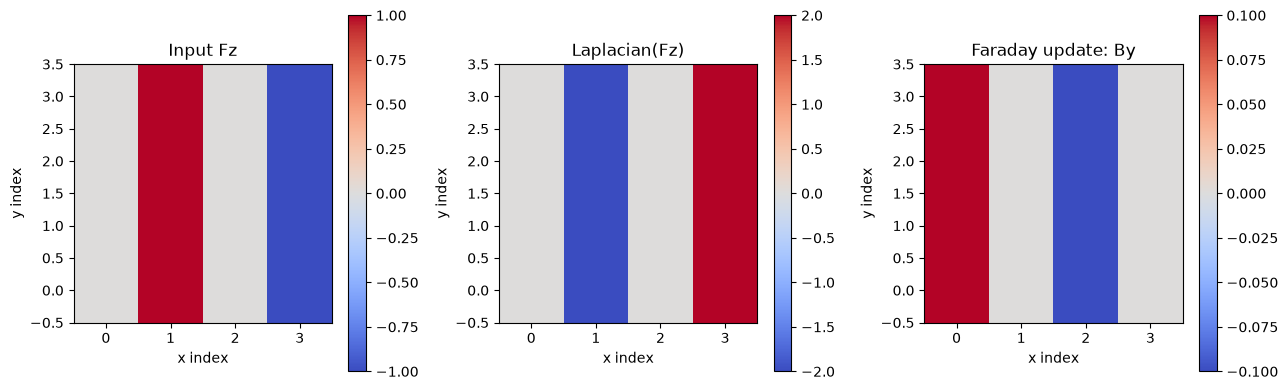

Curl、Laplacian、法拉第更新和场校正均通过。


In [1]:
import os, sys
from pathlib import Path
module_dir = os.environ.get('BORIS_MODULE_DIR')
if module_dir is None:
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent / 'build', parent / 'boris_cpp' / 'build'):
            if list(candidate.glob('boris_cpp*.so')): module_dir = str(candidate); break
        if module_dir: break
sys.path.insert(0, module_dir or '../build')
import matplotlib.pyplot as plt
import boris_cpp as boris
%matplotlib inline

grid = boris.PeriodicGrid(boris.Vec3(0,0,0), boris.Vec3(4,4,0), (4,4,1))
# Fz(x) = [0, 1, 0, -1]，沿 y 方向保持不变。
field = [boris.Vec3(0,0,[0,1,0,-1][i//4]) for i in range(grid.size())]
curl = boris.curl_periodic(grid, field)
lap = boris.laplacian_periodic(grid, field)
assert abs(curl[0].y + 1.0) < 1e-12
assert abs(curl[8].y - 1.0) < 1e-12
assert abs(lap[4].z + 2.0) < 1e-12

zero_magnetic = [boris.Vec3(0,0,0) for _ in range(grid.size())]
magnetic_next = boris.advance_magnetic_faraday(grid, zero_magnetic, field, 0.1)
assert abs(magnetic_next[0].y - 0.1) < 1e-12
assert abs(magnetic_next[8].y + 0.1) < 1e-12

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
def as_image(values, component):
    return [[getattr(values[grid.index(i,j,0)], component) for i in range(4)] for j in range(4)]
for ax, values, component, title in [
    (axes[0], field, 'z', 'Input Fz'), (axes[1], lap, 'z', 'Laplacian(Fz)'),
    (axes[2], magnetic_next, 'y', 'Faraday update: By')]:
    image = ax.imshow(as_image(values, component), origin='lower', cmap='coolwarm')
    ax.set(title=title, xlabel='x index', ylabel='y index')
    fig.colorbar(image, ax=ax)
plt.tight_layout(); plt.show()

# 均匀场没有 curl，零速度和零压力时，校正后的场保持均匀。
data = boris.CorrectionInput()
data.magnetic = [boris.Vec3(0,0,2) for _ in range(grid.size())]
data.electric_half = [boris.Vec3(0,0,0) for _ in range(grid.size())]
data.density = [1.0 for _ in range(grid.size())]
data.bulk_velocity = [boris.Vec3(0,0,0) for _ in range(grid.size())]
data.electron_pressure = [boris.Vec3(0,0,0) for _ in range(grid.size())]
corrected = boris.correct_fields(grid, data, 0.1, 0.0, 0.0)
assert all(b.z == 2 for b in corrected.magnetic)
assert all(e.x == 0 and e.y == 0 and e.z == 0 for e in corrected.electric)
print('Curl、Laplacian、法拉第更新和场校正均通过。')